## AMERICAN COMPANIES BANKRUPTCY PREDICTION

# Project Overview
This project analyses historical financial data of American public companies to predict the likelihood that a company will go bankrupt. The data covers 8,971 companies from 1999 to 2018, and each company is labelled as either alive or failed (bankrupt).
Pr

**Objectives**
- Explore the data to understand which financial indicators differ between failed and alive companies.
- Build and compare predictive models that identify companies at risk of bankruptcy.
- Evaluate the models using metrics suited to imbalanced data.

# Business Statement
Bankruptcy causes major losses for investors, lenders, suppliers and employees. This project provides an early-warning tool that can be used by:

- **Company managers**, to monitor their company's financial health and spot signs of distress early.
- **Investors and shareholders**, to make better decisions when choosing which companies to invest in.
- **Lenders and creditors**, to assess credit risk before offering loans or credit terms.

The aim is to turn financial statement data into a clear signal of whether a company is heading towards failure.

## Data Understanding
The data is sourced from [Kaggle](https://www.kaggle.com/datasets/utkarshx27/american-companies-bankruptcy-prediction-dataset?resource=download). It contains 78,682 records and 21 columns.

**Identifier and target columns**
- **company_name** - Anonymised company identifier 
- **year** - Fiscal year of the record (1999–2018).
- **status_label** -  alive or failed (bankrupt).

**Financial variables**
- **X1 Current assets** - Assets expected to be sold or used in normal business operations within the next year.
- **X2 Cost of goods sold** - The direct cost of producing the goods or services a company sells.
- **X3 Depreciation and amortization** - The gradual loss of value of tangible assets (depreciation) and intangible assets (amortization) over time.
- **X4 EBITDA** - Earnings before interest, taxes, depreciation and amortization. A measure of overall financial performance, often used as an alternative to net income.
- **X5 Inventory** - Goods and raw materials a company holds for production or sale.
- **X6 Net income** - Profit after all expenses and costs have been deducted from total revenue.
- **X7 Total receivables** - Money owed to the company by customers for goods or services already delivered.
- **X8 Market value** - The company's market capitalisation, since the companies are publicly traded.
- **X9 Net sales** - Gross sales minus returns, allowances and discounts.
- **X10 Total assets** - Everything of value that the company owns.
- **X11 Total long-term debt** - Loans and other liabilities that are not due within one year of the balance sheet date.
- **X12 EBIT** - Earnings before interest and taxes.
- **X13 Gross profit** - Revenue left after subtracting the direct costs of producing and selling products or services.
- **X14 Total current liabilities** - Obligations due within one year, such as accounts payable, accrued liabilities, taxes, salaries and commissions.
- **X15 Retained earnings** - Cumulative profit kept in the business after paying costs, taxes and dividends to shareholders.
- **X16 Total revenue** - All income the business earned from sales before expenses are subtracted. It may include interest and dividends from investments.
- **X17 Total liabilities** - The combined debts and obligations the company owes to outside parties.
- **X18 Total operating expenses** - Expenses incurred through normal business operations.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('american_bankruptcy.csv')

In [20]:
df.head(10)

,company_name,status,year,current_assets,cost_of_goods_sold,depreciation_amortization,ebitda,inventory,net_income,total_receivables,...,net_sales,total_assets,long_term_debt,ebit,gross_profit,current_liabilities,retained_earnings,total_revenue,total_liabilities,operating_expenses
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,...,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,...,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,...,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,...,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,...,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467
5,C_1,alive,2004,474.542,598.172,27.950,61.774,255.477,15.453,127.121,...,747.848,732.230,227.159,33.824,149.676,160.025,142.450,747.848,417.486,686.074
6,C_1,alive,2005,624.454,704.081,29.222,91.877,323.592,35.163,136.272,...,897.284,978.819,318.576,62.655,193.203,187.788,183.550,897.284,556.102,805.407
7,C_1,alive,2006,645.721,837.171,32.199,118.907,342.593,58.660,181.691,...,1061.169,1067.633,253.611,86.708,223.998,256.506,242.153,1061.169,573.390,942.262
8,C_1,alive,2007,783.431,1080.895,39.952,168.522,435.608,75.144,202.472,...,1384.919,1362.010,507.918,128.570,304.024,218.499,318.184,1384.919,776.755,1216.397
9,C_1,alive,2008,851.312,1110.677,40.551,166.080,477.424,78.651,227.300,...,1423.976,1377.511,392.984,125.529,313.299,254.418,385.851,1423.976,720.616,1257.896


In [5]:
df.describe()

,year,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18
count,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,7.868200e+04,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000,78682.000000
mean,2007.506317,880.362485,1594.529029,121.234256,376.759424,201.605717,129.382453,286.832743,3.414355e+03,2364.019706,2867.110620,722.483710,255.525035,769.490783,610.072255,532.467069,2364.019706,1773.563963,1987.260307
std,5.742768,3928.564794,8930.484664,652.376804,2012.023142,1060.766096,1265.532022,1335.978571,1.841410e+04,11950.068842,12917.944421,3242.170946,1494.643534,3774.703114,2938.387443,6369.159440,11950.068842,8053.684902,10419.629038
min,1999.000000,-7.760000,-366.645000,0.000000,-21913.000000,0.000000,-98696.000000,-0.006000,1.000000e-04,-1964.999000,0.001000,-0.023000,-25913.000000,-21536.000000,0.001000,-102362.000000,-1964.999000,0.001000,-317.197000
25%,2002.000000,18.924000,17.038250,1.192000,-0.811000,0.000000,-7.415750,3.281250,3.498000e+01,27.548500,37.363500,0.000000,-2.787000,8.521250,8.889250,-68.282750,27.548500,13.486000,32.872500
50%,2007.000000,100.449500,103.661000,7.929500,15.034500,7.023000,1.616000,22.820000,2.275118e+02,186.598500,213.203500,7.593500,6.518000,63.581500,43.333000,-1.131000,186.598500,81.988000,168.912000
75%,2012.000000,431.526750,634.548000,47.971750,139.655250,74.747250,40.144250,131.580500,1.244890e+03,1046.402500,1171.364750,248.760750,87.599000,344.074250,222.817000,146.070000,1046.402500,629.975000,875.522250
max,2018.000000,169662.000000,374623.000000,28430.000000,81730.000000,62567.000000,104821.000000,65812.000000,1.073391e+06,511729.000000,531864.000000,166250.000000,71230.000000,137106.000000,116866.000000,402089.000000,511729.000000,337980.000000,481580.000000


# Data cleaning and inspection

In [10]:
column_names = {
    "company_name": "company_name",
    "status_label": "status",
    "X1": "current_assets",
    "X2": "cost_of_goods_sold",
    "X3": "depreciation_amortization",
    "X4": "ebitda",
    "X5": "inventory",
    "X6": "net_income",
    "X7": "total_receivables",
    "X8": "market_value",
    "X9": "net_sales",
    "X10": "total_assets",
    "X11": "long_term_debt",
    "X12": "ebit",
    "X13": "gross_profit",
    "X14": "current_liabilities",
    "X15": "retained_earnings",
    "X16": "total_revenue",
    "X17": "total_liabilities",
    "X18": "operating_expenses",
}

df = df.rename(columns=column_names)
df.head()


,company_name,status,year,current_assets,cost_of_goods_sold,depreciation_amortization,ebitda,inventory,net_income,total_receivables,...,net_sales,total_assets,long_term_debt,ebit,gross_profit,current_liabilities,retained_earnings,total_revenue,total_liabilities,operating_expenses
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,...,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,...,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,...,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,...,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,...,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   company_name               78682 non-null  str    
 1   status                     78682 non-null  str    
 2   year                       78682 non-null  int64  
 3   current_assets             78682 non-null  float64
 4   cost_of_goods_sold         78682 non-null  float64
 5   depreciation_amortization  78682 non-null  float64
 6   ebitda                     78682 non-null  float64
 7   inventory                  78682 non-null  float64
 8   net_income                 78682 non-null  float64
 9   total_receivables          78682 non-null  float64
 10  market_value               78682 non-null  float64
 11  net_sales                  78682 non-null  float64
 12  total_assets               78682 non-null  float64
 13  long_term_debt             78682 non-null  float64
 14  e

In [19]:
print("Missing values (total):", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate company-year pairs:", int(df.duplicated(["company_name", "year"]).sum()))
print("Unique companies:", df["company_name"].nunique())
print("Years covered:", df["year"].min(), "to", df["year"].max())



Missing values (total): 0
Duplicate rows: 0
Duplicate company-year pairs: 0
Unique companies: 8971
Years covered: 1999 to 2018


The dataset has no missing values nor mismatch in datatypes

In [26]:
df["company_name"].unique()

<StringArray>
[   'C_1',    'C_2',    'C_3',    'C_4',    'C_5',    'C_6',    'C_7',
    'C_8',    'C_9',   'C_10',
 ...
 'C_8962', 'C_8963', 'C_8964', 'C_8965', 'C_8966', 'C_8967', 'C_8968',
 'C_8969', 'C_8970', 'C_8971']
Length: 8971, dtype: str

# Exploratory Data Analysis (EDA)

status
alive     73462
failed     5220
Name: count, dtype: int64
status
alive     93.37 %
failed     6.63 %
Name: count, dtype: str

At company level:
 status
alive     8362
failed     609
Name: count, dtype: int64


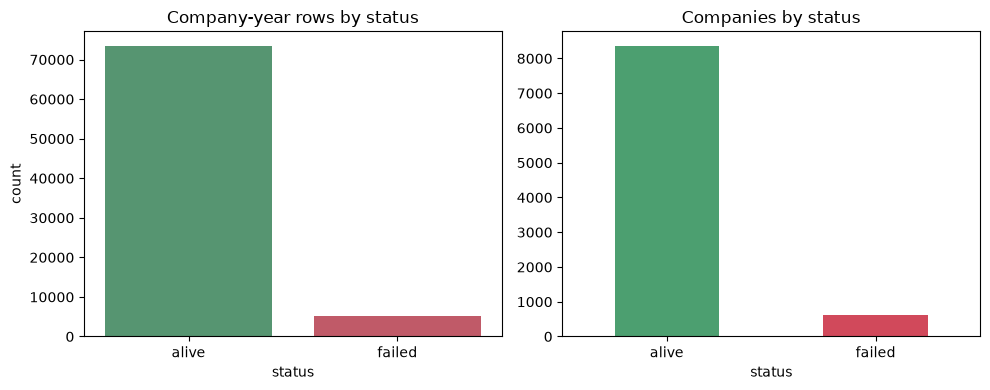

In [ ]:
counts = df["status"].value_counts()
print(count)
print((counts / len(df) * 100).round(2).astype(str) + " %")

company_status = df.groupby("company_name")["status"].first().value_counts()
print("\nAt company level:\n", company_status)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x="status", ax=ax[0], palette=["#4C9F70", "#D1495B"], hue="status", legend=False)
ax[0].set_title("Company-year rows by status")
company_status.plot(kind="bar", ax=ax[1], color=["#4C9F70", "#D1495B"])
ax[1].set_title("Companies by status")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()